# 10.AtomoHidrogeno
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [ ]:
from google.colab import files
from IPython.display import Image
uploaded=files.upload()

Saving faa.png to faa.png


In [1]:
import matplotlib.pyplot as plt           # Paquete gráfico, se grafican las funciones a través de arrays.
from scipy.special import genlaguerre
from scipy import integrate
import numpy as np
from math import factorial

from __future__ import division
import scipy.special as sp
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm, colors

# Constantes en unidades atómicas

h_b = 1     # hbar en unidades atómicas
m_p = 1     # masa de la particula
e=1         # carga del electrón
Z=1         # número de protones
a=1         # radio de Bohr
e_0=1/(4*np.pi)   # Constante de permitividad del vacío

# Energías para el átomo de hidrógeno

def Energia(n):
  for n in range(1,n+1):
    E_n=-(Z**2*e**2)/(8*n**2*a*np.pi*e_0)
    z=np.linspace(0,1,100)
    plt.rcParams["figure.figsize"] = (7, 9)
    plt.plot(z,E_n+(z-z),label='n={:d},  E={:f}'.format(n,round(E_n,6)))
    plt.title('Valores de Energía')
    plt.ylabel('Energía (Hartree)')
    plt.xticks([])
    plt.legend()

# Series espectroscópicas

def Serie(k):
  for n in range(1,13):
    E_n=-(Z**2*e**2)/(8*n**2*a*np.pi*e_0)
    z=np.linspace(0,1,100)
    z1=np.linspace(0.4,0.6,50)
    plt.rcParams["figure.figsize"] = (7, 10)
    plt.plot(z,E_n+(z-z),color='gray',linewidth=1)
    plt.title('Valores de Energía')
    plt.ylabel('Energía (Hartree)')
    plt.xticks([])
    for j in range(k,13):
      E_j=-(Z**2*e**2)/(8*j**2*a*np.pi*e_0)
      plt.plot(z1,E_j+(z1-z1),color='green',linewidth=3)

# Funciones de onda radiales para el átomo de hidrógeno

def Radial(r,n,l):
  L=genlaguerre(n-l-1,2*l+1)
  R=(((factorial(n-l-1)/(2*n*(factorial(n+l))  ))**0.5)*((2/n)**(l+1.5))*(r**l)*(np.exp(-r/n))*L((2*r)/n))
  return R

# Funciones de probabilidad radial para el átomo de hidrógeno

def pRadial(r,n,l):
  L=genlaguerre(n-l-1,2*l+1)
  R=((((factorial(n-l-1)/(2*n*(factorial(n+l))  ))**0.5)*((2/n)**(l+1.5))*(r**l)*(np.exp(-r/n))*L((2*r)/n))**2)*(r**2)
  return R

# Gráfica de las funciones radiales y de densida de probabilidad radial.

def radial(n,l):
  r=np.linspace(0,30,200)
  y=Radial(r,n,l)
  z=pRadial(r,n,l)
  plt.figure(figsize=(12,7))
  plt.plot(r,y,label='$R_{:d}$$_{:d}(r)$'.format(n,l))
  plt.plot(r,z,label='$r^2|R_{:d}$$_{:d}(r)|^2$'.format(n,l))
  plt.grid(True)
  plt.xlabel('r/a')
  plt.title('Función radial $R_{:d}$$_{:d}(r)$ y de distribución de probabilidad radial $r^2|R_{:d}$$_{:d}(r)|^2$ para el átomo de hidrógeno'.format(n,l,n,l))
  plt.legend()

# Probabilidad de encontrar el electrón entra a y b radios de Bohr en el orbital $nl$

def Prob(n,l,a,b):
  sol = integrate.quad(lambda x: pRadial(x,n,l), a, b)
  return sol[0]

# Parte angular de los orbitales hidrogenoides

PHI, THETA = np.mgrid[0:2*np.pi:200j, 0:np.pi:100j] #arrays de variables angulares

def AE(x):
    R = x
    #A continuación convertimos a coordenadas cartesianas
    # para su representación 3D
    X = R * np.sin(THETA) * np.cos(PHI)
    Y = R * np.sin(THETA) * np.sin(PHI)
    Z = R * np.cos(THETA)
    N = R/R.max()    # Normalizar R para que los colores del plot cubran todo el rango del colormap.
    fig, ax = plt.subplots(subplot_kw=dict(projection='3d'), figsize=(12,10))
    im = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, facecolors=cm.jet(N))
    m = cm.ScalarMappable(cmap=cm.jet)
    m.set_array(R)

# **Fuerza central sobre una partícula**

Una fuerza central se origina a causa de una función de energía potencial con simetría esférica. En este caso la función de energía potencial depende solamente de la distancia $r$ de la partícula al centro de simetría del sistema, con lo cual se tiene un Hamiltoniano para una partícula de masa $m$ tiene la siguiente forma

$$\hat{H}=\hat{K}+\hat{V}$$

donde, el operador de energía cinética $\hat{K}$ es igual a $-\frac{\hbar^2}{2m}\nabla^2$ y el de energía potencial $\hat{V}$ es igual a $V(r)$. Utilizando la simetría del sistema, el Hamiltoniano $\hat{H}$ se puede escribir en coordenadas esféricas como

$$\hat{H}=-\frac{\hbar^2}{2m}(\frac{\partial^2}{\partial r^2}+\frac{2}{r}\frac{\partial}{\partial r})+\frac{1}{2mr^2}\hat{L}^2+V(r)$$

donde $\hat{L}^2=-\hbar^2(\frac{\partial^2}{\partial \theta^2}+Cot\theta\frac{\partial}{\partial\theta}+\frac{1}{sen^2\theta}\frac{\partial^2}{\partial\phi^2})$ es el cuadrado del operdor momento angular.  


Es posible verificar que $[\hat{H},\hat{L}^2]=0$, siempre que la energía potencial sea independiente de $\theta$ y $\phi$, el cual es el caso de un potencial $V(r)$ con simetría esférica. La conmutatividad de estos dos operadores nos dice que la energía total del sistema y su momento angular están definidos de forma simultánea, más aún, es posible tener un conjunto de funciones propias simultáneo para $\hat{H}$, $\hat{L}^2$ y $\hat{L}_z$.

Las funciones propias de $\hat{L}^2$ y $\hat{L}_z$ son los armónicos esféricos $Y_{l,m_l}(\theta,\phi)$ y puesto que $\hat{L}^2$  es independiente de $r$, al multiplicar $Y_{l,m_l}$ por una función $R(r)$ que depende de $r$ se seguirá teniendo una función propia de $\hat{L}^2$ y $\hat{L}_z$. Por lo tanto, las funciones propias de $\hat{H}$ son de la forma $R(r)Y_{l,m_l}(\theta,\phi)$, así:

$$\hat{H}R(r)Y_{l,m_l}(\theta,\phi)=ER(r)Y_{l,m_l}(\theta,\phi)$$ \\

$$-\frac{\hbar^2}{2m}(\frac{\partial^2R(r)Y_{l,m_l}(\theta,\phi)}{\partial r^2}+\frac{2}{r}\frac{\partial R(r)Y_{l,m_l}(\theta,\phi)}{\partial r})+\frac{1}{2mr^2}\hat{L}^2R(r)Y_{l,m_l}(\theta,\phi)+V(r)R(r)Y_{l,m_l}(\theta,\phi)=ER(r)Y_{l,m_l}(\theta,\phi)$$ \\

$$-\frac{\hbar^2Y_{l,m_l}(\theta,\phi)}{2m}(\frac{\partial^2R(r)}{\partial r^2}+\frac{2}{r}\frac{\partial R(r)}{\partial r})+\frac{l(l+1)\hbar^2}{2mr^2}R(r)Y_{l,m_l}(\theta,\phi)+V(r)R(r)Y_{l,m_l}(\theta,\phi)=ER(r)Y_{l,m_l}(\theta,\phi)$$ \\

$$-\frac{\hbar^2}{2m}(\frac{\partial^2R(r)}{\partial r^2}+\frac{2}{r}\frac{\partial R(r)}{\partial r})+\frac{l(l+1)\hbar^2}{2mr^2}R(r)+V(r)R(r)=ER(r)$$ \\

En conclusión se tiene que cualquier problema de una partícula con una función de energía potencial de simetría esférica $V(r)$ tiene como funciones de onda estacionarías $R(r)Y_{l,m_l}(\theta,\phi)$, donde el valor radial satisface la última ecuación diferencial de la secuencia anterior. Empleando una forma específica para $V(r)$ se resuelve está ecuación y consecuentemente se soluciona el operador Hamiltoniano para este problema partícular.

# **Átomo de Hidrógeno**


El problema del átomo de hidrogenoide consiste en la descripción del comportamiento de un único electrón sometido a la atracción del núcleo. Para átomos de más de un electrón no es posible obtener una solución exacta de la ecuación de Schrödinger, debido a las repulsiones interelectrónicas.

El operador de energía potencial del electrón de carga $-e$ sometido a la interacción de un núcleo con $Z$ protones, tiene la forma

$$V(r)=-\frac{1}{4\pi\epsilon}\frac{Ze^2}{r}$$

donde, $\epsilon=8.8541878*10^{-12}C^2N^{-1}m^{-2}$ es la constante de permitividad del vacío. En este sistema de dos partículas con masas $m_N$ y $m_e$ la energía cinética es la suma de la energía cinética debida a la traslación del sistema de masa total $M=m_N+m_e$ localizada en el centro de masas y la energía cinética del movimiento relativo (interno) de las dos partículas. Como la energía potencial de este sistema de partículas depende solamente de las coordenadas relativas de las partículas, se puede reducir este problema a uno de una partícula de masa $\mu=\frac{m_Nm_e}{m_N+m_e}$ sujeta a la función de energía potencial $V(r)$, para el que sus coordenadas $(r,\theta,\phi)$ son las coordenadas polares esféricas de una partícula con respecto a la otra. El movimiento traslacional del átomo como un todo añade simplemente una constante a la energía total del sistema.

Como el potencial $V$ depende solamente de $r$, este es un problema de fuerza central de una partícula y por lo tanto las funciones propias del Hamiltoniano tienen la forma

$$\psi(r,\theta,\phi)=R(r)Y_{l,m_l}(\theta,\phi)$$

donde $\psi(r,\theta,\phi)$ satisface la ecuación diferencial

$$-\frac{\hbar^2}{2m}(\frac{\partial^2R(r)}{\partial r^2}+\frac{2}{r}\frac{\partial R(r)}{\partial r})+\frac{l(l+1)\hbar^2}{2mr^2}R(r)+V(r)R(r)=ER(r)$$

reemplazando $m=\mu$, $e'=\frac{e}{\sqrt{4\pi\varepsilon}}$ y $a=\frac{\hbar^2}{\mu e'^2}$, esta ecuación toma la forma

$$R''-\frac{2}{r}R'+[\frac{2E}{ae'^2}+\frac{2Z}{ar}-\frac{l(l+1)}{r^2}]R=0$$

Esta ecuación es la $\textbf{ecuación radial para el átomo de hidrógeno}$ y es la única ecuación nueva que es obtiene para encontrar las soluciones completas al Hamiltoniano del átomo de hidrógeno. De la forma de esta ecuación se deduce que la energía total $E$ es igual a la suma de la energía cinética radial, la energía cinética angular y la energía potencial.

En la busqueda de las soluciones se obtiene que la energía debe estar cuantizada de acuerdo con

$$E_n=-\frac{Z^2\mu e'^4}{2n^2\hbar^2}=-\frac{Z^2 e^2}{8\pi\epsilon an^2}$$

para $n=1,2,,3,4,...$. En la solución de la ecuación radial no solamente el entero $n$ ocurre de forma natural, este también debe satisfacer la condición

$$0\leq l\leq n-1 \ \ \ \ \ n=1,2,3,...$$

Las soluciones de la ecuación radial dependen de los números cuánticos $n$ y $l$ y están dadas por

$$R_{nl}(r)=[\frac{(n-l-1)!}{2n(n+l)!}]^{1/2}(\frac{2}{na})^{l+3/2}r^le^{-r/na}L^{2l+1}_ {n-l-1}(\frac{2r}{na})$$

donde, $L^{2l+1}_ {n-l-1}(\frac{2r}{na})$ son las funciones asociadas de Laguerre.

El factor combinatorio de $R_{nl}(r)$ no asegura que estas funciones están normalizadas, es decir

$$\int_0^{\infty}R_{nl}^{*}(r)R_{nl}(r)r^2dr=1$$

como se esta trabajando en coordenadas esféricas el elemento de volumen $r^2sin\theta drd\theta d\phi$ es igual a $r^2dr$.

## Ejercicio 1

La función $Energia(n)$, arroja los valores de energía de los $n$ primeros estados del átomo de hidrógeno. Emplee está función para diferentes valores de $n$ y explique su comportamiento.

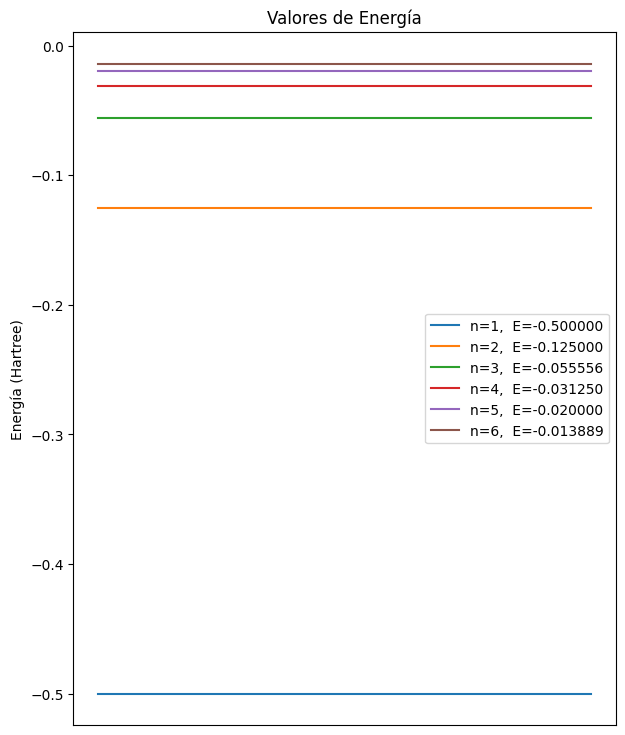

In [2]:
Energia(6)

## Ejercicio 2

La función $Serie(k)$ arroja un grafico espectral de energías. Emplee está función para $k=1,2,3,4,5,6$ y describa lo que sucede. ¿Qué dice la literatura al respecto?

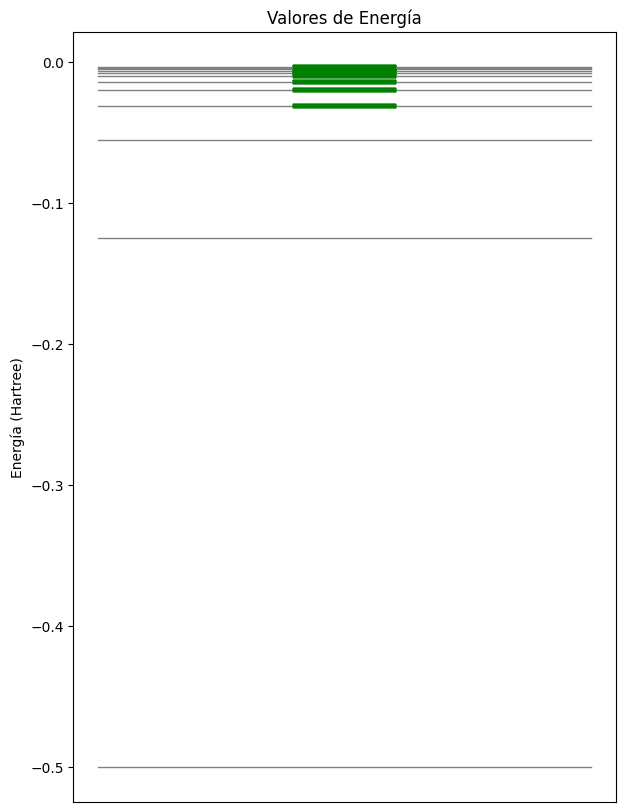

In [3]:
Serie(4)

## **Funciones radiales**

Las funciones de onda del átomo de hidrógeno $\psi_{nlm_l}(r,\theta,\phi)=R_{nl}(r)Y_{l,m_l}(\theta,\phi)$ dependen de tres números cuánticos: $n$, $l$ y $m_l$, que satisfacen

$$n=1,2,3,4,... \  \  \  \  0\leq l \leq n-1 \ \ y \ \ |m_l|\leq l$$

El número cuántico $n$ se llama $\textbf{número cuántico principal}$ y la energía $E_n=-\frac{Z^2 e^2}{8\pi\epsilon an^2}$ depende solamente de este número cuántico. El número cuántico $l$ se llama $\textbf{número cuántico azimutal o de momento angular}$. El momento angular del electrón con respecto al protón está determinado completamente por $l$ a través de la expresión $|L|=\hbar\sqrt{l(l+1)}$. Note que la forma de las funciones radiales depende solamente de $n$ y $l$. Se acostumbra a denotar el valor de $l$ con una letra, $l=0$ se denota por $s$, $l=1$ por $p$, $l=2$ por $d$, $l=3$ por $f$ y los valores siguientes de $l$ se siguen denotando por la secuencia del alfabeto que le sigue a $f$, es decir, por $g$, $h$, $i$, etc. El origen de las letras $s$, $p$, $d$ y $f$ es histórico y se relaciona con la designación de las lineas espectrales del átomo de sodio. Estas significan: sharp, principal, diffuse y fundamental. Una función de onda con $n=1$ y $l=0$ se denota por $1s$, una con $n=2$ y $l=0$ por $2s$ y así sucesivamente.

El número cuántico $m_l$ se llama $\textbf{número cuántico magnético}$ y toma los $2l+1$ valores $m_l=0,\pm 1,\pm 2,...,\pm l$. La componente $z$ del momento angular está completamente determinada by $m_l$, a través de la expresión $|L_z|=m_l\hbar$. El número cuántico $m_l$ se llama magnético por la energía del átomo de hidrógeno en un campo magnético depende de $m_l$. Las $2l+1$ degeneraciones en la ausencia de un campo magnético se descomponen en $2l+1$ energías diferentes en la presencia de una campo magnético, y esta descomposición depende de los $2l+1$ valores que puede tomar $m_l$.

Como la función de onda $\psi_{nlm_l}(r,\theta,\phi)$ del átomo de hidrógeno depende de tres variables no es posible vusualizarla en el espacio $3$-dimensional, ya que el grafo de $\psi_{nlm_l}$ vive en el espacio $4$-dimensional $\mathbb{R}^4$. Por ello es usual considerar las partes radial y angular por separado.  

Como se menciono antes las funciones radiales están normalizadas y por lo tanto

$$\int_0^{\infty}R_{nl}^{*}(r)R_{nl}(r)r^2dr=\int_0^{\infty}[R_{nl}(r)]^2r^2dr=1$$

esto nos indica que la probabilidad de que el electrón se encuentre en la región comprendida entre $r$ y $r+dr$ es $[R_{nl}(r)]^2r^2dr$.




## Ejercicio 3

La función $radial(n,l)$ arroja las gráficas de la función radial $R_{nl}(r)$ y de distribución de probabilidad radial $r^2|R_{nl}(r)|^2$ para el átomo de hidrógeno. Utilice esta función para visualizar el comportamiento radial de las funciones de onda $1s$, $2s$, $2p$, $3s$, $3p$, $3d$, $4s$, $4p$, $4d$ y $4f$. Analice su comportamiento y deduzca el número de nodos en estás funciones. ¿Qué significado tienen los nodos?, ¿que significado tienen los puntos máximos de $r^2|R_{nl}(r)|^2$?  

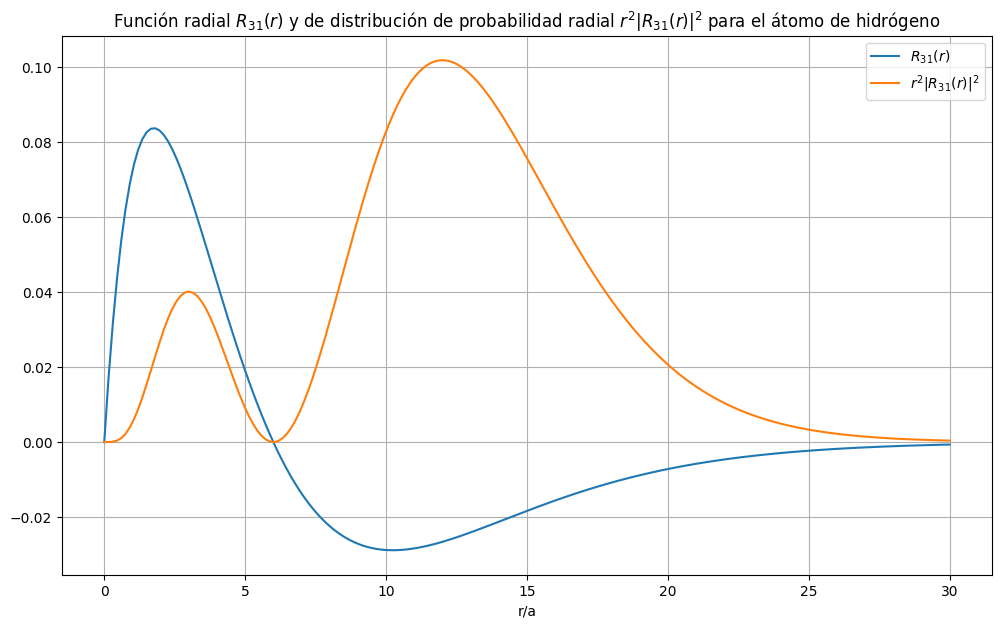

In [4]:
radial(3,1)

## Ejercicio 4

Para un electrón del átomo de hidrógeno que se encuentra en el orbital $nl$, la función $Prob(n,l,a,b)$ arroja la probabilidad de encontrar este electrón entre $a$ y $b$ radios de Bohr.

1. Encuentre la probabilidad de que un electrón en el orbital $1s$ se encuentre a menos de $1$ radio de Bohr del núcleo.

2. Encuentre la probabilidad de que un electrón en el orbital $1s$ se encuentre a menos de $2$ radios de Bohr del núcleo.

3. Encuentre la probabilidad de que un electrón en el orbital $3d$ se encuentre a menos de $10$ radios de Bohr del núcleo.

Nota: recuerde que en unidades atómicas $a=1$.

## **Funciones hidrogenoides reales**

Los armónicos esféricos $Y_{lm_l}(\theta,\phi)$ son complejos excepto para $m=0$. Para no emplear funciones imaginarias se utilizan a menudo funciones de onda hidrogenoides reales, formadas mediante combinaciones lineales de las funciones complejas. Esta elección es válida ya que cualquier combinación lineal de funciones propias de un nivel de energía degenerado es una función propia del Hamiltoniano con el mismo valor propio. Como la energía del átomo de hidrógeno no depende de $m$, los estados $2p_1$ y $2p_{-1}$ pertenecen a un nivel de energía degenerado, y cualquier combinación lineal de estos es una función propia del Hamiltoniano con el mismo vamor propio de la energía. Una forma de combinar estas funciones para obtener una función real es la siguiente:

$$\psi_{2p_x}=\frac{1}{\sqrt{2}}(\psi_{2p_{-1}}+\psi_{2p_1})=\frac{1}{4\sqrt{2\pi}}(\frac{Z}{a})^{5/2}re^{-Zr/2a}sen\theta cos\phi$$

La siguiente figura muestra la combinación de armónicos esféricos utilizada para obtener orbitales hidrogenoides reales.

In [ ]:
Prob(1,0,.5,1)

0.24302218674554246

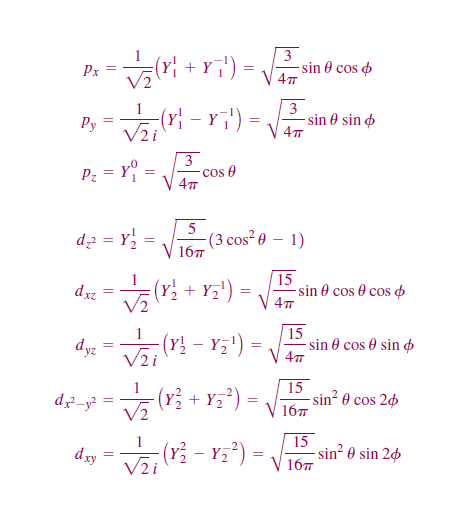

In [ ]:
#@title
Image(filename='faa.png', width=500, height=550)
# Figura tomada de: Engel T., Quantum Chemistry and Spectroscopy, Pearson, 1996.


Para representarlas graficamente las funciones de onda hidrogenoides necesitamos cuatro dimensiones, ya que estas dependen de $r$, $\theta$ y $\phi$. Como nuestro espacio es tridimensional hacemos las graficas de los factores de $\psi_{nlm_l}(r,\theta,\phi)$ de forma independiente. Como se hizo antes representamos la parte radial $R_{nl}(r)$ frente a $r/a$, la cual no contienen información sobre la variación angular de $\psi_{nlm_l}$.

Para obtener la probabilidad de encontrar en electrón en la posición $(\theta,\phi)$ utilizamos la combinación de armónicos esféricos de la tabla anterior.
La función $AE(x)$ nos da una representación gráfica de la parte angular de estas funciones hidrogenoides reales. Para utilizar está función su argumento $x$ debe remplazarce por la función correspondiente. En la siguiente celda puedes ver un ejemplo.

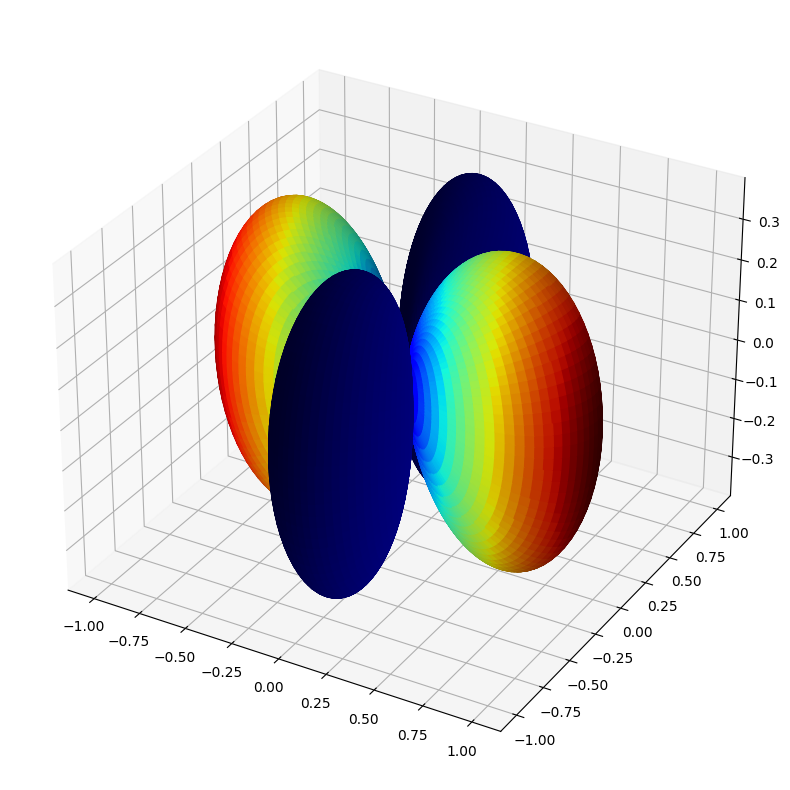

In [5]:
AE((np.sin(THETA))**2*np.cos(2*PHI))

$\textbf{Observación:}$ las funciones seno y coseno se digitan como: np.sin y np.cos


Algunos textos dicen que la gráfica anterior corresponde a la forma de los orbitales $d_{x^2-y^2}$, lo cual es incorrecto. Esta figura es simplemente la representación gráfica del factor angular de una función de onda.

## Ejercicio 5

Utilice la función $AE(x)$ para hacer la representación gráfica de la parte angular de los orbitales atómicos hidrogenoides.

In [ ]:
AE(np.cos(THETA))